# Manpower July 2024: incidents per unit

Analysis of OPD unit activity, 1-29 July 2024 (18-19 July excluded):
- how many incidents each unit takes on in a day 
- how long each incident takes.

The data ends at 29 July (OPD switched to a new CAD system on 30 July), and this log comes from the old one. 18 and 19 July are dropped entirely (CAD outage night).

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
from box_utils import BOX_ROOT

DATA = BOX_ROOT / "OPD & TAN - Core Workspace" / "OPD - Oakland Police Dept" / "Data" / "Our Data"

july2024 = pd.read_csv(DATA / "Man_Power_2024_July_matched_codes.csv", parse_dates=["Manpower_Record_Time"],
                       dtype={"unit_beat": str}, low_memory=False)

print(july2024.shape)

(174975, 31)


In [50]:
# Global filters for both analyses
# 1. Keep patrol beat cars only (is_patrol)
# 2. Keep status rows only (Record_Type 2); roster and disposition rows have no duration
patrol = july2024[july2024["is_patrol"] & (july2024["Record_Type"] == 2)]
print(patrol.shape)

(70513, 31)


### Incidents per day

count     27.0
mean     137.8
std       22.1
min       99.0
25%      123.0
50%      136.0
75%      150.5
max      197.0
dtype: float64


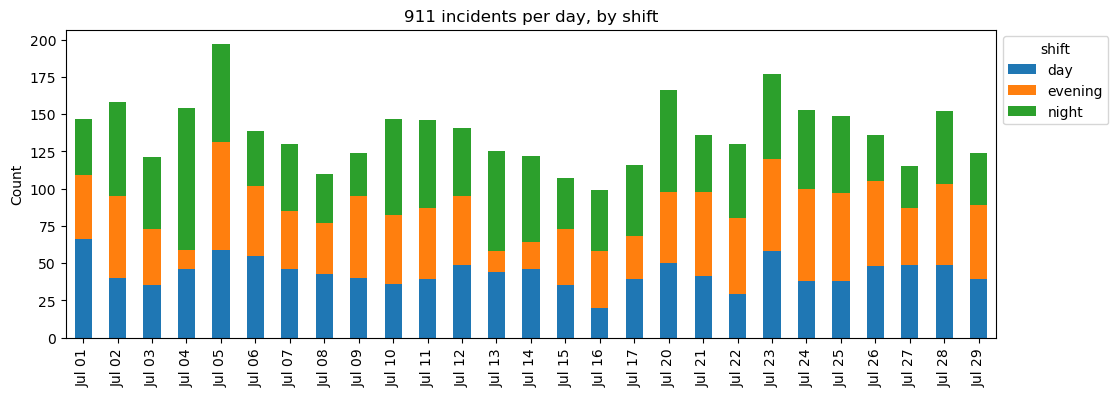

In [51]:
# 911 incidents per day: distinct CAD events (matched_incident_number) that patrol cars worked,
# dated by when they first appear in the log, split by the shift of the first car on it

# one row per incident: its earliest log time and the shift of that first car
events = (patrol[patrol["call_source"] == "911 CALL"].sort_values("Manpower_Record_Time")
                .groupby("matched_incident_number")
                .agg(first_seen=("Manpower_Record_Time", "first"), shift=("shift", "first")))
# date label, e.g. "Jul 01"
events["date"] = events["first_seen"].dt.strftime("%b %d")

# number of incidents per day and shift; columns ordered bottom to top of the stack
per_day = events.groupby(["date", "shift"]).size().unstack()[["day", "evening", "night"]]
print(per_day.sum(axis=1).describe().round(1))

per_day.plot(kind="bar", stacked=True, figsize=(12, 4))
plt.title("911 incidents per day, by shift")
plt.xlabel("")
plt.ylabel("Count")
plt.legend(title="shift", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### How many incidents each unit takes on in a day

In [52]:
# 1. Give each row a shift instance: every log on (UO) starts a new shift for that unit
# Need to do this because each unit id may be used again in another day  
rows = patrol.sort_values(["Unit_ID", "Manpower_Record_Time", "Manpower_PK"]).copy()
rows["shift_number"] = (rows["Code"] == "UO").groupby(rows["Unit_ID"]).cumsum()

# 2. Count distinct incidents per shift instance
# list of shifts: each shift has exactly one log on (UO) row, so the UO rows give one row per shift
shifts = rows[rows["Code"] == "UO"].set_index(["Unit_ID", "shift_number"])[["shift"]]
# readable names for the four call sources
SOURCE = {
    "911 CALL":             "911",
    "DEFAULT - PHONE INIT": "non-emergency phone",
    "FIELD INITIATED BY D": "field-initiated",
    "MDT-INITIATED":        "MDT-initiated",
}
# count unique incidents in each shift for each call source, and add the counts to the list (0 if none)
counts = rows.groupby(["Unit_ID", "shift_number", "call_source"])["Incident_FK"].nunique().unstack()
shifts = shifts.join(counts.rename(columns=SOURCE)).fillna(0)

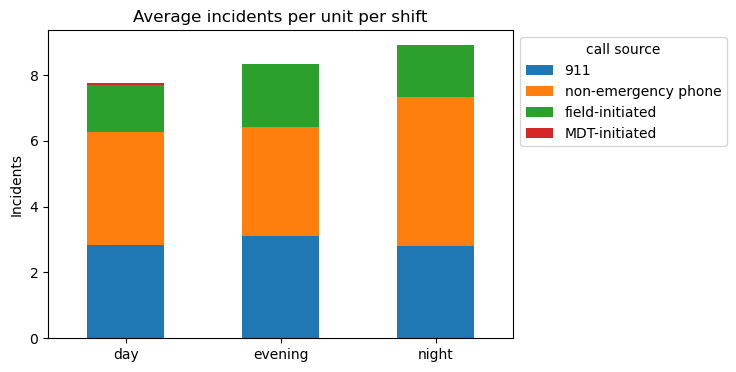

In [53]:
# 3. Plot: average incidents per unit per shift, stacked by call source
avg = shifts.groupby("shift")[list(SOURCE.values())].mean().loc[["day", "evening", "night"]]
avg.plot(kind="bar", stacked=True, rot=0, figsize=(6, 4))
plt.title("Average incidents per unit per shift")
plt.xlabel("")
plt.ylabel("Incidents")
plt.legend(title="call source", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### How long each incident takes 

In [54]:
# 1. Keep only time spent working the incident:
#    drop "available" (already cleared), reassign / freed (instant handovers) and at-station rows;
#    status updates (UU) take the status they continue
work = patrol.copy()
work["code_category"] = work["code_category"].replace("status update", pd.NA)
work["code_category"] = work.groupby("Unit_ID")["code_category"].ffill()
work = work[~work["code_category"].isin(["available", "assignment change", "out of service"])]

# 2. Time per unit per incident: sum Seconds_At_Status over that unit's rows on the incident (rows with no incident drop out),
#    in minutes and split by code_category; one row per unit x incident
minutes = (work.groupby(["shift", "shift_hours", "Unit_ID", "Incident_FK", "code_category"])["Seconds_At_Status"].sum() / 60)
minutes = minutes.unstack(fill_value=0).reset_index()

# shift label with its hours, e.g. "day (6/7am-4/5pm)"
minutes["shift_label"] = minutes["shift"] + " (" + minutes["shift_hours"] + ")"
# stages of working an incident, in time order
STAGES = ["officer-initiated", "en route to call", "on scene", "transporting a person",
          "en route to facility", "at facility", "special assignment"]
# total minutes the unit spent on the incident, start to finish
minutes["total"] = minutes[STAGES].sum(axis=1)

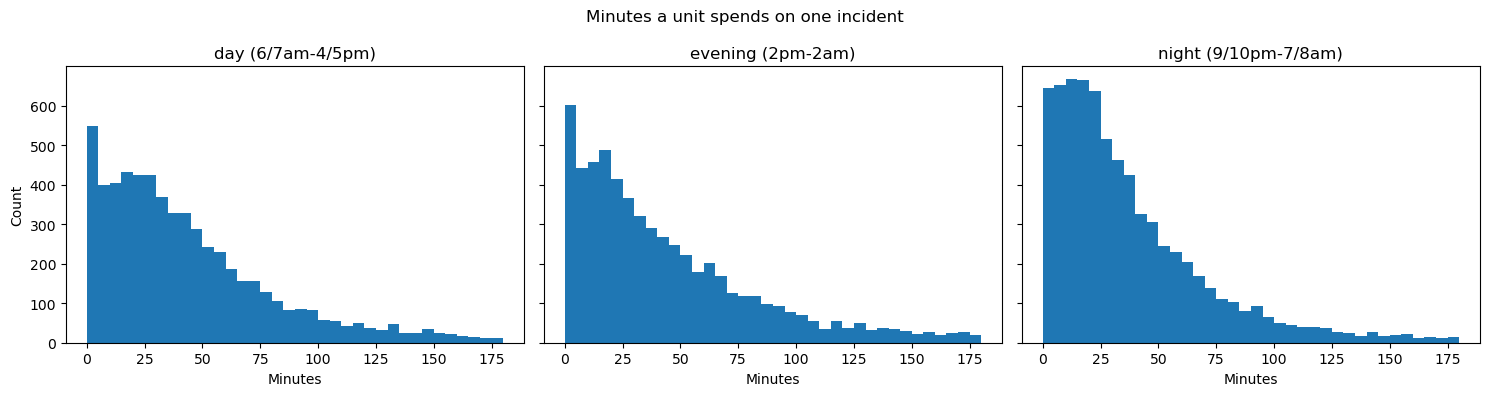

In [57]:
# 3. Plot: how long a unit spends on one incident, start to finish, one histogram per shift (shown up to 3 hours)
SHIFT_LABELS = minutes.drop_duplicates("shift").set_index("shift")["shift_label"][["day", "evening", "night"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, label in zip(axes, SHIFT_LABELS):
    ax.hist(minutes.loc[minutes["shift_label"] == label, "total"], bins=36, range=(0, 180))
    ax.set_title(label)
    ax.set_xlabel("Minutes")
axes[0].set_ylabel("Count")
fig.suptitle("Minutes a unit spends on one incident")
plt.tight_layout()
plt.show()

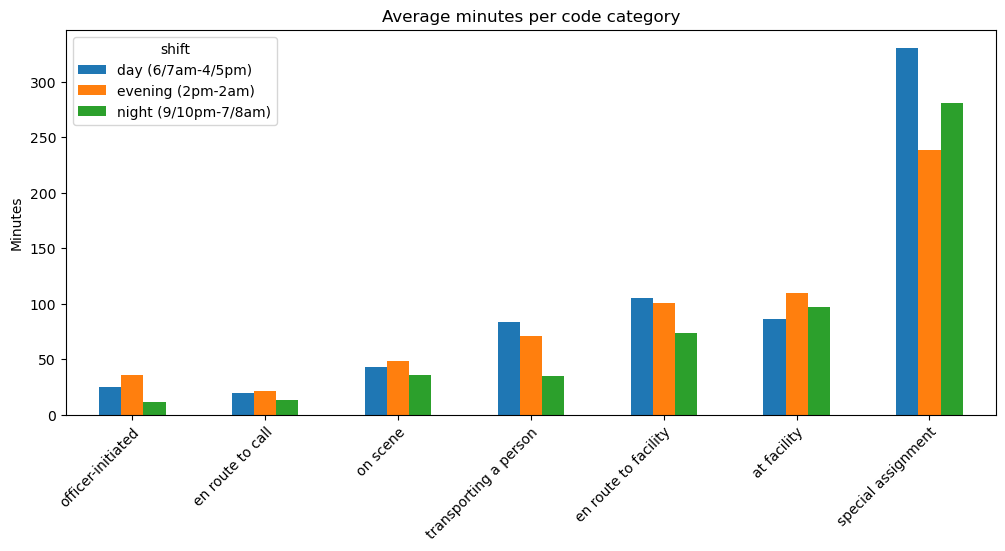

In [56]:
# 4. Plot: average minutes in each code category (only incidents where that stage happened), by shift
stage_avg = minutes[STAGES].where(minutes[STAGES] > 0).groupby(minutes["shift_label"]).mean().loc[SHIFT_LABELS]
stage_avg.T.plot(kind="bar", figsize=(12, 5))
plt.xticks(rotation=45, ha="right", rotation_mode="anchor")
plt.title("Average minutes per code category")
plt.xlabel("")
plt.ylabel("Minutes")
plt.legend(title="shift")
plt.show()

In [ ]:
# NEED TO CONTINUE THIS BUT WITH JUST THE 911 CALLS 